# Heart disease prediction on the UCI Cleveland dataset

Predicting whether a patient has heart disease from 13 routine clinical measurements.
Cardiovascular disease is one of the leading causes of death worldwide, so the useful
version of this problem is not "how accurate can the model be" but "how few sick
patients does it miss". A false negative here is a patient sent home who should not have
been, so recall on the disease class is the metric I care about most.

The data is the Cleveland subset of the UCI Heart Disease dataset, 303 patients. Six
rows have missing values in `ca` or `thal`, which I drop, leaving 297. The original
target runs 0 to 4 (severity); I collapse it to a straight presence (1) or absence (0),
which is how this dataset is almost always used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

## Loading the data

The raw file has no header. These are the standard column names for the Cleveland set.
Missing values are marked with `?`, so I read those as NaN.

In [2]:
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target",
]

df = pd.read_csv("data/processed.cleveland.data", header=None, names=COLUMNS, na_values="?")
print("raw shape:", df.shape)
print("missing per column:")
print(df.isna().sum()[df.isna().sum() > 0])

raw shape: (303, 14)
missing per column:
ca      4
thal    2
dtype: int64


In [3]:
# Drop the handful of rows with missing values, then binarize the target.
df = df.dropna().reset_index(drop=True)
df["target"] = (df["target"] > 0).astype(int)

print("clean shape:", df.shape)
print("class balance:")
print(df["target"].value_counts(normalize=True).round(3))
df.head()

clean shape: (297, 14)
class balance:
target
0    0.539
1    0.461
Name: proportion, dtype: float64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


A quick word on the columns, because the names are terse:

- `cp` chest pain type, `trestbps` resting blood pressure, `chol` serum cholesterol
- `fbs` fasting blood sugar over 120, `restecg` resting ECG result
- `thalach` max heart rate achieved, `exang` exercise induced angina
- `oldpeak` ST depression on exercise, `slope` slope of the ST segment
- `ca` number of major vessels colored by fluoroscopy, `thal` thalassemia result

The classes are close to balanced (about 54% no disease, 46% disease), which is a relief
after the 3% positive rate I am used to on equipment failure data. It means accuracy is
not actively misleading here, but I still lead with recall for the clinical reason above.

## What correlates with disease

Before modelling, a correlation heatmap. I am mainly looking at the bottom row, how each
feature moves with the target.

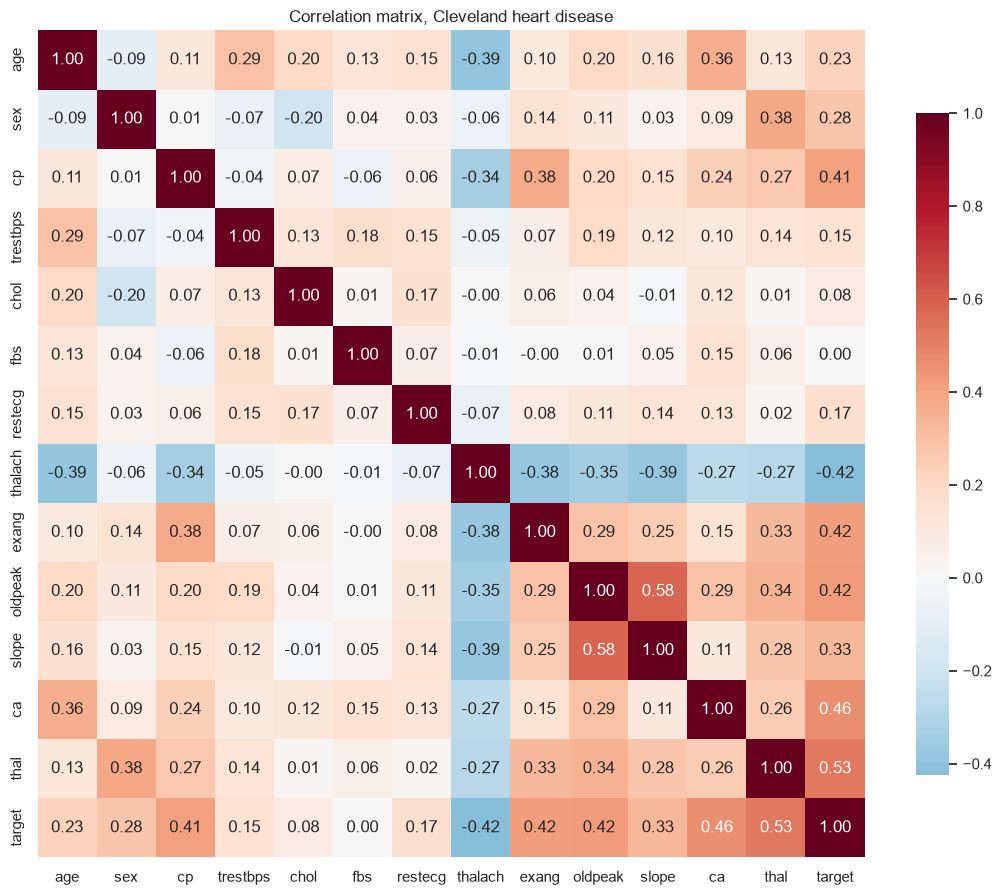

In [4]:
plt.figure(figsize=(11, 9))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix, Cleveland heart disease")
plt.tight_layout()
plt.savefig("figures/correlations.png", dpi=110, bbox_inches="tight")
plt.show()

The strongest signals line up with clinical intuition. `thalach` (max heart rate) is
negatively correlated with disease, lower peak heart rate goes with disease. `cp`,
`exang`, `oldpeak`, `ca` and `thal` all carry real signal in the other direction. Nothing
is so strongly correlated that it looks like leakage, which is what I am checking for.

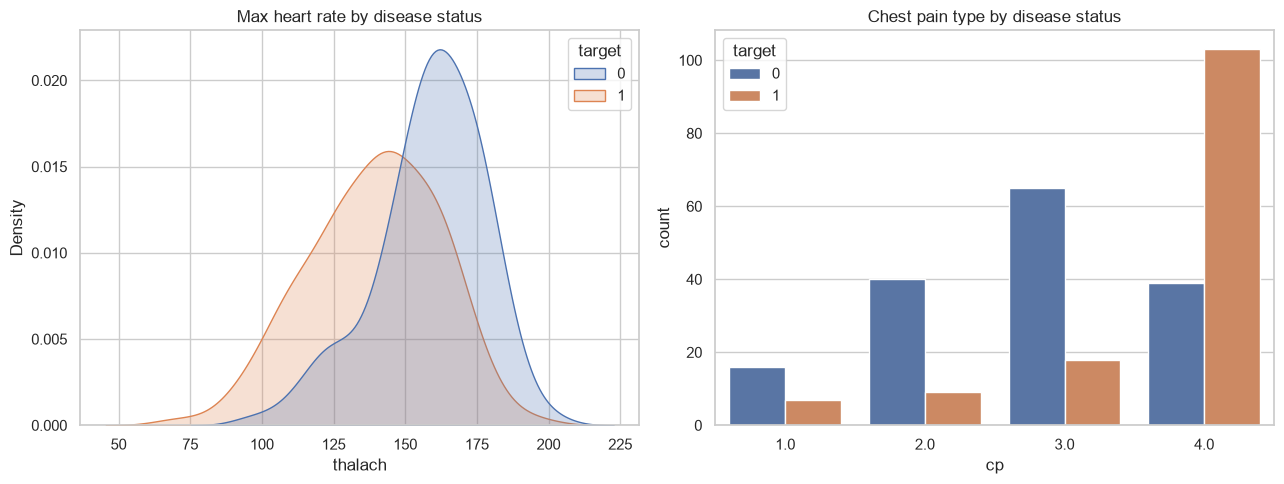

In [5]:
# A couple of distributions that show the separation clearly.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.kdeplot(data=df, x="thalach", hue="target", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("Max heart rate by disease status")
sns.countplot(data=df, x="cp", hue="target", ax=axes[1])
axes[1].set_title("Chest pain type by disease status")
plt.tight_layout()
plt.savefig("figures/distributions.png", dpi=110, bbox_inches="tight")
plt.show()

## Modelling

A stratified 80/20 split so both classes are represented in the test set. I scale the
features for the logistic regression baseline, then compare it against a random forest.
The forest does not need scaling but it does no harm to pass it the same frame.

In [6]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_s, y_train)

rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

print("models trained")

models trained


In [7]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }

lr_prob = logreg.predict_proba(X_test_s)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]

results = pd.DataFrame([
    evaluate("logistic regression", y_test, logreg.predict(X_test_s), lr_prob),
    evaluate("random forest", y_test, rf.predict(X_test), rf_prob),
]).set_index("model").round(3)
results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
logistic regression,0.833,0.846,0.786,0.815,0.950
random forest,0.867,0.885,0.821,0.852,0.943


## ROC curves

With classes this balanced, ROC-AUC is a fair summary. The curve also helps me pick a
threshold later.

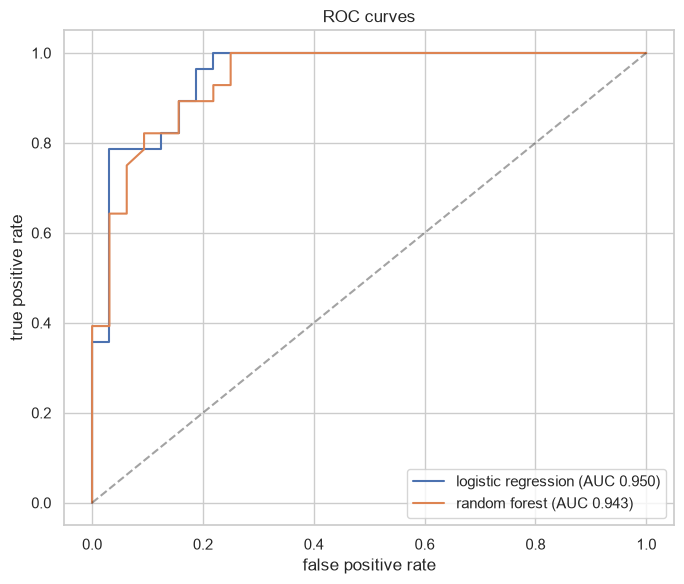

In [8]:
plt.figure(figsize=(7, 6))
for name, prob in [("logistic regression", lr_prob), ("random forest", rf_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/roc_curves.png", dpi=110, bbox_inches="tight")
plt.show()

## Which model, and why recall drives the choice

The two models are close on AUC. The logistic regression is a strong baseline here
precisely because the decision boundary is close to linear in these features. I take the
logistic regression forward as the primary model: it is competitive, it is calibrated
enough to move the threshold sensibly, and it is interpretable, which matters a lot in a
clinical setting where someone will ask "why did it flag this patient".

The default 0.5 threshold is not sacred. Because a missed diagnosis is worse than a false
alarm, I look at what happens when I lower the threshold to buy recall.

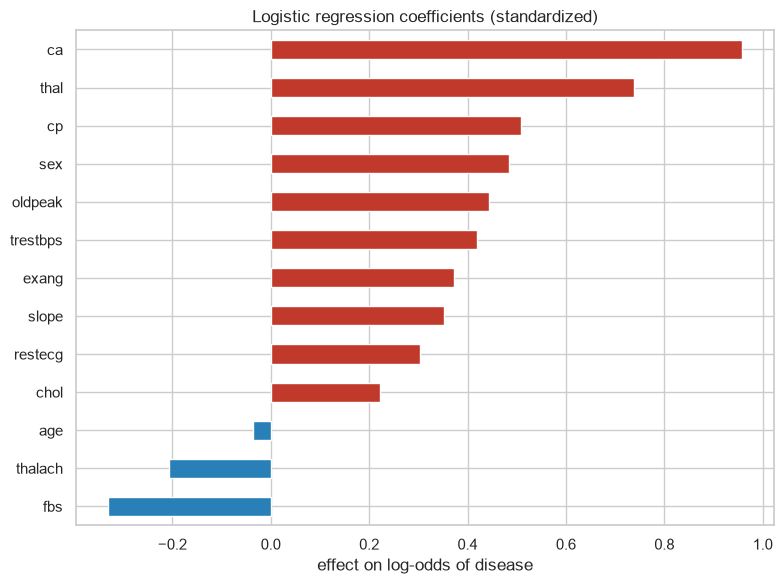

In [9]:
# Feature effects from the logistic regression (standardized coefficients).
coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(8, 6))
coef.plot(kind="barh", color=np.where(coef > 0, "#c0392b", "#2980b9"))
plt.title("Logistic regression coefficients (standardized)")
plt.xlabel("effect on log-odds of disease")
plt.tight_layout()
plt.savefig("figures/feature_effects.png", dpi=110, bbox_inches="tight")
plt.show()

In [10]:
# Threshold tuning on the logistic regression: push recall up.
TUNED = 0.35
y_pred_tuned = (lr_prob >= TUNED).astype(int)

print(f"default threshold 0.50 vs tuned {TUNED}")
print("recall  :", round(recall_score(y_test, logreg.predict(X_test_s)), 3),
      "->", round(recall_score(y_test, y_pred_tuned), 3))
print("precision:", round(precision_score(y_test, logreg.predict(X_test_s)), 3),
      "->", round(precision_score(y_test, y_pred_tuned), 3))
print()
print(classification_report(y_test, y_pred_tuned, target_names=["no disease", "disease"]))

default threshold 0.50 vs tuned 0.35
recall  : 0.786 -> 0.893
precision: 0.846 -> 0.833

              precision    recall  f1-score   support

  no disease       0.90      0.84      0.87        32
     disease       0.83      0.89      0.86        28

    accuracy                           0.87        60
   macro avg       0.87      0.87      0.87        60
weighted avg       0.87      0.87      0.87        60



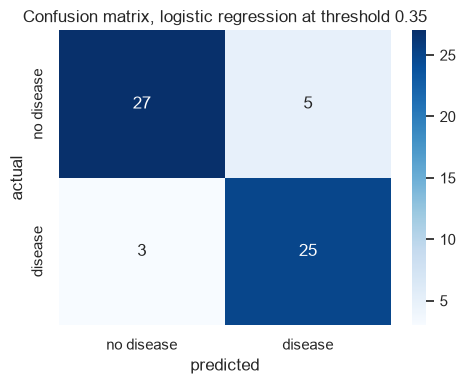

In [11]:
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["no disease", "disease"],
            yticklabels=["no disease", "disease"])
plt.title(f"Confusion matrix, logistic regression at threshold {TUNED}")
plt.ylabel("actual")
plt.xlabel("predicted")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

## Saving the model

I persist the scaler and the model together so the inference side does not have to
remember the preprocessing. The small Streamlit app in `app.py` loads exactly this file.

In [12]:
import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)
joblib.dump({"scaler": scaler, "model": logreg, "columns": list(X.columns),
             "threshold": TUNED}, "model/heart_model.joblib")
print("saved model/heart_model.joblib")

saved model/heart_model.joblib


## Honest limitations

- This is 297 patients from one study in the late 1980s. It is a classic teaching dataset,
  not current clinical practice, and the feature definitions (for example `thal`) are
  specific to how this study was run.
- With a test set of 60 patients, a single reclassified case moves recall by almost two
  points, so I would not over read small differences between the models.
- A real deployment would need calibration against the local population, a prospective
  validation rather than a random split, and sign off from people who actually treat
  patients. This is a modelling exercise, not a medical device.